<a href="https://colab.research.google.com/github/PiyushAgrawal05/Phoneme-Recognition-Model-WavLM-ConBiMamba-LoRA-MoE/blob/main/MDD_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mispronunciation Detection and Diagnosis (MDD)
## Stage 1: Pure-Acoustic Phoneme Recognition and Experimental Analysis

This notebook contains the final model setup and post-training analysis for the WavLM–ConBiMamba–Frame-Level LoRA-MoE phoneme recognizer.

The current scope is **acoustic phoneme recognition and analysis**. It includes model restoration, frame-level expert-routing analysis, speaker-wise and L1-wise recognition performance, and phoneme-level error analysis.

The notebook does not retrain the model and does not yet implement complete phone-level mispronunciation localization or articulatory diagnosis.

### Workflow
1. Configure the environment and authenticate with Hugging Face.
2. Load the saved test predictions and reconstruct the L2-Arctic test split.
3. Define the phoneme vocabulary and the original perceived-IPA mapping.
4. Reconstruct and load the trained model checkpoint.
5. Run A1–A10 expert-routing analysis.
6. Run speaker-wise, L1-wise and phoneme-level error analysis.
7. Upload all derived artifacts to the private Hugging Face analysis repository.

**Training code is intentionally excluded from this analysis notebook. Keep the original training notebook as a separate archive.**

## Phase 1: Environment and Hugging Face Cloud Configuration

Install only the libraries required for dataset access, model reconstruction, checkpoint loading and analysis. The Colab-provided PyTorch/CUDA installation is left untouched to avoid replacing a working GPU build.

In [1]:
%pip install -q "datasets==4.8.5" "transformers==5.22.1" "huggingface_hub==1.33.0" "jiwer==4.0.0" pandas matplotlib

### Hugging Face Authentication and Repository Configuration

The trained model checkpoint is downloaded from the existing model repository. Predictions and derived analysis artifacts are stored in a separate private Dataset repository.

No Google Drive connection is required.

In [2]:
from pathlib import Path
import json
import shutil
import hashlib

from huggingface_hub import (
    login,
    HfApi,
    hf_hub_download
)
from huggingface_hub.errors import EntryNotFoundError

# Authenticate with a Hugging Face token that has read access
# to the model repository and write access to the private analysis repository.
login()

api = HfApi()

# Existing trained model repository
PRETRAINED_REPO = "hsuyip05/wavlm-conbimamba-lora-moe"

# Separate private repository for predictions and analysis artifacts
REPO_ID = "hsuyip05/mdd-analysis-artifacts"

api.create_repo(
    repo_id=REPO_ID,
    repo_type="dataset",
    private=True,
    exist_ok=True
)

# Verify visibility explicitly: exist_ok=True does not change an existing
# repository's visibility. Switch it to Private in Hugging Face settings if needed.
analysis_repo_info = api.repo_info(
    repo_id=REPO_ID,
    repo_type="dataset"
)
if not analysis_repo_info.private:
    raise RuntimeError(
        f"{REPO_ID} is not private. Change its visibility to Private "
        "in Hugging Face before uploading prediction/analysis artifacts."
    )

def load_checkpoint(filename):
    """Download a model checkpoint from the trained model repository."""
    return hf_hub_download(
        repo_id=PRETRAINED_REPO,
        filename=filename,
        repo_type="model"
    )

print("Hugging Face authentication and repository setup complete.")
print("Model repository:", PRETRAINED_REPO)
print("Analysis repository:", REPO_ID)

Hugging Face authentication and repository setup complete.
Model repository: hsuyip05/wavlm-conbimamba-lora-moe
Analysis repository: hsuyip05/mdd-analysis-artifacts


### Local Working Folder and Cloud Prediction Retrieval

The working folder exists only inside the Colab runtime. The verified prediction JSON is retrieved from the private Hugging Face Dataset repository and copied into this folder so that all final artifacts can be uploaded together.

On the first run only, if the prediction JSON is not yet present in the repository, the cell asks for a one-time local upload and then stores it in Hugging Face. Later sessions download it automatically.

In [24]:
project_dir = Path("/content/MDD_Project")
project_dir.mkdir(parents=True, exist_ok=True)

PREDICTION_FILENAME = "final_360_test_predictions.json"
PREDICTION_REPO_PATH = f"results/{PREDICTION_FILENAME}"
prediction_file = project_dir / PREDICTION_FILENAME

try:
    cached_prediction_path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=PREDICTION_REPO_PATH
    )
    shutil.copy2(cached_prediction_path, prediction_file)
    print("Predictions downloaded from Hugging Face.")

except EntryNotFoundError:
    print(
        "The prediction JSON is not yet in the analysis repository. "
        "Select final_360_test_predictions.json for the one-time upload."
    )
    from google.colab import files

    uploaded_files = files.upload()

    if PREDICTION_FILENAME not in uploaded_files:
        raise FileNotFoundError(
            f"Please upload a file named {PREDICTION_FILENAME}."
        )

    prediction_file.write_bytes(uploaded_files[PREDICTION_FILENAME])

    api.upload_file(
        path_or_fileobj=str(prediction_file),
        path_in_repo=PREDICTION_REPO_PATH,
        repo_id=REPO_ID,
        repo_type="dataset"
    )
    print("Initial prediction JSON uploaded to Hugging Face.")

with open(prediction_file, "r", encoding="utf-8") as f:
    prediction_data = json.load(f)

references = prediction_data["references"]
predictions = prediction_data["predictions"]

assert len(references) == 360
assert len(predictions) == 360

prediction_sequence_hash = hashlib.sha256(
    json.dumps(
        prediction_data,
        ensure_ascii=False,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

EXPECTED_PREDICTION_HASH = (
    "5281ed165060c54ebca01d4af9bbd67"
    "cd3de7ae33ef43d3562f7fd057233f369"
)

assert prediction_sequence_hash == EXPECTED_PREDICTION_HASH, (
    "Prediction sequence hash mismatch. Do not continue with analysis."
)

print("Verified predictions loaded:", len(references))
print("Sequence SHA-256:", prediction_sequence_hash)
print("Local working folder:", project_dir)

final_360_test_predictions.json:   0%|          | 0.00/62.4k [00:00<?, ?B/s]

Predictions downloaded from Hugging Face.
Verified predictions loaded: 360
Sequence SHA-256: 5281ed165060c54ebca01d4af9bbd67cd3de7ae33ef43d3562f7fd057233f369
Local working folder: /content/MDD_Project


## Phase 2: Phoneme Vocabulary

The recognizer uses a fixed 41-class output vocabulary: CTC blank at index 0, 39 CMU ARPAbet phonemes at indices 1–39, and unknown at index 40. The mapping must remain consistent with the saved checkpoint and the stored reference/prediction sequences.

In [4]:
# Cell 5: Vocabulary Definition and Mapping (Fixed 41-Class Indexing)
import re

cmu_phonemes = [
    "AA", "AE", "AH", "AO", "AW", "AY", "B", "CH", "D", "DH", "EH", "ER",
    "EY", "F", "G", "HH", "IH", "IY", "JH", "K", "L", "M", "N", "NG", "OW",
    "OY", "P", "R", "S", "SH", "T", "TH", "UH", "UW", "V", "W", "Y", "Z", "ZH"
]

# Strictly reserve 0 for CTC <blank> and 40 for <unk>
vocab_dict = {"<blank>": 0}
for i, phn in enumerate(cmu_phonemes):
    vocab_dict[phn] = i + 1
vocab_dict["<unk>"] = 40

id_to_vocab = {v: k for k, v in vocab_dict.items()}

def clean_phoneme(phn):
    phn = re.sub(r'\d+', '', str(phn)).strip().upper()
    return phn if phn in vocab_dict else "<unk>"

print(f"Vocabulary initialized with {len(vocab_dict)} classes (Blank index: {vocab_dict['<blank>']}, Unk index: {vocab_dict['<unk>']}).")

Vocabulary initialized with 41 classes (Blank index: 0, Unk index: 40).


### L2-Arctic Test Split Reconstruction

Reconstruct the same deterministic 80/10/10 split from the `scripted` L2-Arctic dataset using seed 42. The complete test split is retained in its original order because A6 extracts routing metadata in this order and the speaker/L1 analysis aligns that metadata with the saved prediction sequences.

In [5]:
from datasets import load_dataset

l2_dataset = load_dataset(
    "KoelLabs/L2Arctic",
    split="scripted"
)

l2_train_test = l2_dataset.train_test_split(
    test_size=0.2,
    seed=42
)

l2_val_test = l2_train_test["test"].train_test_split(
    test_size=0.5,
    seed=42
)

test_dataset = l2_val_test["test"]

assert len(test_dataset) == 360, (
    f"Expected 360 test utterances, found {len(test_dataset)}."
)

print("L2-Arctic test split reconstructed.")
print("Test utterances:", len(test_dataset))
print("Dataset columns:", test_dataset.column_names)

README.md:   0%|          | 0.00/3.93k [00:00<?, ?B/s]

data/spontaneous-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 50.0MB            

data/spontaneous-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/scripted-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  423MB            

data/scripted-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating spontaneous split:   0%|          | 0/22 [00:00<?, ? examples/s]

Generating scripted split:   0%|          | 0/3599 [00:00<?, ? examples/s]

L2-Arctic test split reconstructed.
Test utterances: 360
Dataset columns: ['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language']


### Perceived IPA-to-ARPAbet Mapping for Alignment Verification

The original L2-Arctic perceived-IPA parser is retained here solely to verify that the saved reference sequences correspond to the reconstructed test split in the same order. The native-speech G2P and training data pipelines are not needed in this analysis notebook.

The parser is a many-to-one mapping to ARPAbet and skips characters that do not match its mapping table. The equality check in the next cell verifies consistency with the saved references under this same parser; it does not make the IPA-to-ARPAbet conversion lossless.


In [6]:
import re

# Preserve the original longest-first perceived IPA to ARPAbet mapping.
IPA_TO_ARPABET = [
    ("tʃ", "CH"), ("dʒ", "JH"), ("aɪ", "AY"), ("aʊ", "AW"), ("ɔɪ", "OY"),
    ("eɪ", "EY"), ("oʊ", "OW"), ("əʊ", "OW"), ("ɝ", "ER"), ("ɚ", "ER"),
    ("ɜɹ", "ER"), ("əɹ", "ER"), ("ɑ", "AA"), ("ɒ", "AA"), ("a", "AA"),
    ("æ", "AE"), ("ʌ", "AH"), ("ə", "AH"), ("ɐ", "AH"), ("ɜ", "ER"),
    ("ɔ", "AO"), ("ɛ", "EH"), ("e", "EY"), ("ɪ", "IH"), ("i", "IY"),
    ("ʊ", "UH"), ("u", "UW"), ("ʉ", "UW"), ("o", "OW"),
    ("b", "B"), ("d", "D"), ("ɾ", "D"), ("ð", "DH"), ("f", "F"),
    ("ɡ", "G"), ("g", "G"), ("h", "HH"), ("ɦ", "HH"), ("x", "HH"),
    ("j", "Y"), ("k", "K"), ("l", "L"), ("ɫ", "L"), ("m", "M"),
    ("n", "N"), ("ɲ", "N"), ("ŋ", "NG"), ("p", "P"), ("ɹ", "R"),
    ("r", "R"), ("ɻ", "R"), ("s", "S"), ("ʃ", "SH"), ("t", "T"),
    ("ʔ", "T"), ("θ", "TH"), ("v", "V"), ("w", "W"), ("ʍ", "W"),
    ("z", "Z"), ("ʒ", "ZH")
]

def ipa_to_arpabet_ids(ipa_str):
    # Keep the same parser behavior as the original training/evaluation pipeline.
    s = re.sub(r'[ˈˌːˑ͜͡\s]', '', str(ipa_str))
    ids = []
    i = 0
    while i < len(s):
        matched = False
        for ipa_tok, arpa_tok in IPA_TO_ARPABET:
            if s.startswith(ipa_tok, i):
                ids.append(vocab_dict[arpa_tok])
                i += len(ipa_tok)
                matched = True
                break
        if not matched:
            i += 1
    return ids

### Reference-to-Dataset Order Audit

Before matching speaker/L1 metadata to the saved PER results, verify the saved reference sequences against the perceived-IPA annotations in the reconstructed test split. This prevents silent metadata misalignment if the dataset split or ordering changes.

In [7]:
dataset_references = []

for ipa_text in test_dataset["ipa"]:
    label_ids = ipa_to_arpabet_ids(ipa_text)
    label_tokens = [
        id_to_vocab[int(token_id)]
        for token_id in label_ids
        if int(token_id) != 0
        and id_to_vocab.get(int(token_id), "")
        not in ["", "<blank>", "<unk>"]
    ]
    dataset_references.append(" ".join(label_tokens))

assert len(dataset_references) == 360
assert dataset_references == references, (
    "Dataset reference order/content does not match the saved prediction JSON. "
    "Stop before speaker/L1 analysis."
)

print("Reference sequence order verified against the reconstructed L2-Arctic test split.")


Reference sequence order verified against the reconstructed L2-Arctic test split.


## Phase 3: Model Architecture and Checkpoint Restoration

The model is restored only for the expert-routing analysis. The saved prediction sequences are used for the speaker/L1 and phoneme-level PER analyses; those analyses do not rerun model inference.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Computation device:", device)

Computation device: cuda


### Hybrid WavLM–ConBiMamba–Frame-Level LoRA-MoE Architecture

The recognizer combines a pretrained WavLM-Base-Plus acoustic backbone, learnable fusion of the 13 hidden representations, six-expert frame-level LoRA-MoE adapters in the intermediate and output projections of the final six WavLM Transformer layers, and four custom bidirectional gated/convolutional acoustic sequence blocks.

An intermediate CTC head follows the second sequence block, while the final CTC head follows the fourth block. The model produces 41 output classes.

**Terminology note:** `BiMambaAcousticBlock` is a project-specific Mamba-inspired gated/convolutional block, not a canonical Mamba selective state-space module. Its `d_state` constructor argument is currently unused. The model architecture and checkpoint parameter names are otherwise unchanged.

In [9]:
# Cell 11: Frame-Level LoRA-MoE Routing + Acoustic-Anchored WavLM-ConBiMamba
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import WavLMModel

class LoRAMoELinear(nn.Module):
    """6-Expert Frame-Level Low-Rank Adaptation Mixture-of-Experts for Acoustic Projections."""
    def __init__(self, base_linear: nn.Linear, num_experts=6, rank=8, alpha=16.0):
        super().__init__()
        self.base_linear = base_linear
        for param in self.base_linear.parameters():
            param.requires_grad = False

        in_features = base_linear.in_features
        out_features = base_linear.out_features
        self.scaling = alpha / rank

        self.lora_A = nn.Parameter(torch.randn(num_experts, in_features, rank) * 0.02)
        self.lora_B = nn.Parameter(torch.zeros(num_experts, rank, out_features))
        self.router = nn.Linear(in_features, num_experts)

    def forward(self, x):
        # x: [Batch, Time, Dim]
        base_out = self.base_linear(x)
        # Frame-level acoustic routing weights: [Batch, Time, K]. Each acoustic
        # frame receives its own expert mixture; frames are not phone-aligned labels.
        gate_weights = F.softmax(self.router(x), dim=-1)
        # Compute expert outputs: [Batch, Time, K, Out]
        expert_outs = torch.einsum('bti,kir,kro->btko', x, self.lora_A, self.lora_B) * self.scaling
        moe_delta = torch.sum(expert_outs * gate_weights.unsqueeze(-1), dim=2)
        return base_out + moe_delta


class BiMambaAcousticBlock(nn.Module):
    """Custom bidirectional gated/convolutional acoustic block inspired by Mamba-style processing.

    This is not a canonical Mamba selective state-space implementation. The
    d_state argument is retained in the constructor but is not used by the
    current block implementation.
    """
    def __init__(self, d_model=256, d_state=16, conv_kernel=31, dropout=0.1):
        super().__init__()
        self.ffn1 = nn.Sequential(
            nn.LayerNorm(d_model), nn.Linear(d_model, d_model * 2),
            nn.SiLU(), nn.Dropout(dropout), nn.Linear(d_model * 2, d_model), nn.Dropout(dropout)
        )
        self.norm_ssm = nn.LayerNorm(d_model)
        self.in_proj = nn.Linear(d_model, d_model * 2)
        self.fwd_conv = nn.Conv1d(d_model, d_model, kernel_size=3, padding=1, groups=d_model)
        self.bwd_conv = nn.Conv1d(d_model, d_model, kernel_size=3, padding=1, groups=d_model)
        self.dt_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

        self.norm_conv = nn.LayerNorm(d_model)
        self.dw_conv = nn.Sequential(
            nn.Conv1d(d_model, d_model, kernel_size=conv_kernel, padding=conv_kernel // 2, groups=d_model),
            nn.BatchNorm1d(d_model), nn.SiLU(), nn.Conv1d(d_model, d_model, kernel_size=1), nn.Dropout(dropout)
        )
        self.ffn2 = nn.Sequential(
            nn.LayerNorm(d_model), nn.Linear(d_model, d_model * 2),
            nn.SiLU(), nn.Dropout(dropout), nn.Linear(d_model * 2, d_model), nn.Dropout(dropout)
        )
        self.final_norm = nn.LayerNorm(d_model)

    def _selective_scan(self, u, conv_layer):
        # u: [B, T, D]
        u_conv = F.silu(conv_layer(u.transpose(1, 2)).transpose(1, 2))
        delta = torch.sigmoid(self.dt_proj(u_conv))
        # Custom gated one-step temporal mixing. This is not a canonical SSM scan.
        u_prev = F.pad(u_conv[:, :-1, :], (0, 0, 1, 0))
        return u_conv * delta + (1.0 - delta) * 0.35 * u_prev

    def forward(self, x):
        x = x + 0.5 * self.ffn1(x)
        res = x
        x_norm = self.norm_ssm(x)
        u, z = self.in_proj(x_norm).chunk(2, dim=-1)
        y_fwd = self._selective_scan(u, self.fwd_conv)
        y_bwd = torch.flip(self._selective_scan(torch.flip(u, dims=[1]), self.bwd_conv), dims=[1])
        x = res + self.out_proj((y_fwd + y_bwd) * F.silu(z))

        x_c = self.norm_conv(x).transpose(1, 2)
        x = x + self.dw_conv(x_c).transpose(1, 2)
        x = x + 0.5 * self.ffn2(x)
        return self.final_norm(x)


class HybridWavLMConBiMambaMoE(nn.Module):
    def __init__(self, d_model=256, num_classes=41, num_experts=6, lora_rank=8):
        super().__init__()
        self.wavlm = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
        for param in self.wavlm.parameters():
            param.requires_grad = False

        # Inject 6-Expert Frame-Level LoRA-MoE into ALL 12 Transformer layers!
        for layer in self.wavlm.encoder.layers[-6:]:
            layer.feed_forward.intermediate_dense = LoRAMoELinear(layer.feed_forward.intermediate_dense, num_experts, lora_rank)
            layer.feed_forward.output_dense = LoRAMoELinear(layer.feed_forward.output_dense, num_experts, lora_rank)

        init_weights = torch.zeros(13)
        init_weights[-1] = 4.0
        init_weights[-2] = 4.0
        self.layer_weights = nn.Parameter(init_weights)

        self.proj = nn.Sequential(
            nn.LayerNorm(768),
            nn.Linear(768, d_model),
            nn.Dropout(0.1)
        )
        self.spec_drop = nn.Dropout1d(0.10)

        self.layers = nn.ModuleList([BiMambaAcousticBlock(d_model=d_model) for _ in range(4)])
        self.inter_ctc_head = nn.Linear(d_model, num_classes)
        self.final_ctc_head = nn.Linear(d_model, num_classes)

    def forward(self, raw_waveforms, input_lengths):
        out_lengths = self.wavlm._get_feat_extract_output_lengths(input_lengths).to(raw_waveforms.device)
        max_len = raw_waveforms.size(1)
        attn_mask = torch.arange(max_len, device=raw_waveforms.device).unsqueeze(0) < input_lengths.unsqueeze(1)

        outputs = self.wavlm(raw_waveforms, attention_mask=attn_mask.long(), output_hidden_states=True)

        # Normalize each hidden state across feature dim so mid-layers (L6-L10) have equal variance to L11-L12!
        normed_hs = [F.layer_norm(h, (768,)) for h in outputs.hidden_states]
        stacked_hs = torch.stack(normed_hs, dim=0)
        num_hs = stacked_hs.size(0)
        active_weights = self.layer_weights[:num_hs]
        norm_weights = F.softmax(active_weights, dim=0).view(num_hs, 1, 1, 1)
        weighted_features = (stacked_hs * norm_weights).sum(dim=0)

        x = self.proj(weighted_features)

        if self.training:
            x = self.spec_drop(x.transpose(1, 2)).transpose(1, 2)

        inter_logits = None
        for idx, layer in enumerate(self.layers):
            x = layer(x)
            if idx == 1:
                inter_logits = self.inter_ctc_head(x).transpose(0, 1)

        final_logits = self.final_ctc_head(x).transpose(0, 1)
        return final_logits, inter_logits, out_lengths

### Model Initialization and Architecture Check

Initialize the exact architecture before loading the trained Stage 2 checkpoint. The dummy forward pass checks that the expected model dimensions and output structure are available.

In [10]:
# Cell 13: Initialize Hybrid Model and Verify Dimensions
model = HybridWavLMConBiMambaMoE(d_model=256, num_classes=41, num_experts=6, lora_rank=8).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

dummy_wav = torch.randn(2, 32000).to(device)  # 2 seconds of 16kHz audio
dummy_len = torch.tensor([32000, 24000]).to(device)

with torch.no_grad():
    final_logits, inter_logits, out_lengths = model(dummy_wav, dummy_len)

print(f"Total Parameters    : {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,} ({100 * trainable_params / total_params:.2f}%)")
print(f"Final Logits Shape  : {final_logits.shape} | Output Frame Lengths: {out_lengths.tolist()}")

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


Total Parameters    : 100,423,959
Trainable Parameters: 6,042,023 (6.02%)
Final Logits Shape  : torch.Size([99, 2, 41]) | Output Frame Lengths: [99, 74]


## Phase 4: Final Checkpoint and Expert-Routing Analysis

### A1: Load the Final Stage 2 SWA Checkpoint

Restore the previously trained Stage 2 SWA weights from the Hugging Face model repository. No optimizer, training loop or parameter update is executed in this notebook.

In [11]:
# Cell A1: Load Final Stage 2 SWA Checkpoint

import torch
import torch.nn.functional as F

# Load the final Stage 2 SWA checkpoint
checkpoint_path = load_checkpoint("wavlm_conbimamba_stage2_swa.pth")
checkpoint_state = torch.load(checkpoint_path, map_location=device)

# Restore the trained model
load_status = model.load_state_dict(checkpoint_state, strict=True)
model.eval()

print("Stage 2 SWA checkpoint loaded successfully!")
print(f"Model device: {device}")

# Identify all independent LoRA-MoE modules
moe_modules = {
    name: module
    for name, module in model.named_modules()
    if isinstance(module, LoRAMoELinear)
}

print(f"\nTotal LoRA-MoE modules: {len(moe_modules)}")

assert len(moe_modules) == 12, (
    f"Expected 12 MoE modules, found {len(moe_modules)}"
)

for name, module in moe_modules.items():
    print(f"{name} -> {module.router.out_features} experts")

wavlm_conbimamba_stage2_swa.pth: reconstructing file:   0%|          |  0.00B /  402MB            

wavlm_conbimamba_stage2_swa.pth: downloading bytes:           |  0.00B            

Stage 2 SWA checkpoint loaded successfully!
Model device: cuda

Total LoRA-MoE modules: 12
wavlm.encoder.layers.6.feed_forward.intermediate_dense -> 6 experts
wavlm.encoder.layers.6.feed_forward.output_dense -> 6 experts
wavlm.encoder.layers.7.feed_forward.intermediate_dense -> 6 experts
wavlm.encoder.layers.7.feed_forward.output_dense -> 6 experts
wavlm.encoder.layers.8.feed_forward.intermediate_dense -> 6 experts
wavlm.encoder.layers.8.feed_forward.output_dense -> 6 experts
wavlm.encoder.layers.9.feed_forward.intermediate_dense -> 6 experts
wavlm.encoder.layers.9.feed_forward.output_dense -> 6 experts
wavlm.encoder.layers.10.feed_forward.intermediate_dense -> 6 experts
wavlm.encoder.layers.10.feed_forward.output_dense -> 6 experts
wavlm.encoder.layers.11.feed_forward.intermediate_dense -> 6 experts
wavlm.encoder.layers.11.feed_forward.output_dense -> 6 experts


### Cell A2: Frame-Level Expert Routing Extraction

* **Purpose:** Extracts the six expert routing probabilities generated independently by each LoRA-MoE module.
* **Operations:** Registers forward hooks on all 12 routing networks to capture their frame-level softmax probabilities without modifying the model architecture or its learned parameters.

In [12]:
# Cell A2: Register Hooks to Capture Expert Routing Weights

# Remove previous hooks if this cell is executed again
if "router_hook_handles" in globals():
    for handle in router_hook_handles:
        handle.remove()

router_capture = {}
router_hook_handles = []

def make_router_hook(name):
    def hook(module, inputs, output):
        weights = F.softmax(output.detach().float(), dim=-1)
        router_capture[name] = weights.cpu()
    return hook

# Register hooks on all 12 independent routers
for name, moe_module in moe_modules.items():
    handle = moe_module.router.register_forward_hook(
        make_router_hook(name)
    )
    router_hook_handles.append(handle)

print(f"Registered {len(router_hook_handles)} routing hooks.")
print("Each router captures 6 expert probabilities per acoustic frame.")

Registered 12 routing hooks.
Each router captures 6 expert probabilities per acoustic frame.


### Cell A3: Routing Extraction Sanity Check

* **Purpose:** Verifies that the registered hooks correctly capture expert routing probabilities during model inference.
* **Operations:** Runs a sample L2-Arctic utterance through the trained model and checks the dimensions and probability distribution of all captured routing weights.

In [13]:
# Cell A3: Verify Routing Weight Extraction

# Select one sample from the original L2-Arctic test split
probe_sample = l2_val_test["test"][0]

probe_audio = torch.as_tensor(
    probe_sample["audio"]["array"],
    dtype=torch.float32,
    device=device
)

assert probe_audio.ndim == 1, "Expected mono audio."
assert probe_sample["audio"]["sampling_rate"] == 16000, (
    "Expected audio sampled at 16 kHz."
)

probe_length = torch.tensor(
    [probe_audio.numel()],
    dtype=torch.long,
    device=device
)

# Apply the same per-utterance normalization used during evaluation
probe_audio = (
    probe_audio - probe_audio.mean()
) / (probe_audio.std() + 1e-5)

probe_audio = probe_audio.unsqueeze(0)

# Capture routing probabilities during inference
router_capture.clear()

with torch.inference_mode():
    _ = model(probe_audio, probe_length)

# Verify captured outputs
assert len(router_capture) == 12, (
    f"Expected 12 router outputs, received {len(router_capture)}"
)

print("Expert Routing Extraction Successful!\n")

for name, weights in router_capture.items():
    probability_error = (
        weights.sum(dim=-1) - 1.0
    ).abs().max().item()

    print(
        f"{name}\n"
        f"  Shape: {tuple(weights.shape)}\n"
        f"  Maximum probability-sum error: {probability_error:.8f}"
    )

print("\nAll 12 routers verified.")

Expert Routing Extraction Successful!

wavlm.encoder.layers.6.feed_forward.intermediate_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000018
wavlm.encoder.layers.6.feed_forward.output_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000012
wavlm.encoder.layers.7.feed_forward.intermediate_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000024
wavlm.encoder.layers.7.feed_forward.output_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000012
wavlm.encoder.layers.8.feed_forward.intermediate_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000012
wavlm.encoder.layers.8.feed_forward.output_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000012
wavlm.encoder.layers.9.feed_forward.intermediate_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000012
wavlm.encoder.layers.9.feed_forward.output_dense
  Shape: (1, 221, 6)
  Maximum probability-sum error: 0.00000012
wavlm.encoder.layers.10.f

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


### Cell A4: Inspecting L2-Arctic Speaker and Language Metadata

* **Purpose:** Identifies the speaker information and native-language labels available in the L2-Arctic test split.
* **Operations:** Examines dataset columns and extracts unique speaker and native-language values to prepare for speaker-wise and L1-wise expert activation analysis.

In [14]:
# Cell A4: Inspect L2-Arctic Metadata

test_dataset = l2_val_test["test"]

print("Total test utterances:", len(test_dataset))
print("\nAvailable dataset columns:")
print(test_dataset.column_names)

# Inspect one sample
sample = test_dataset[0]

print("\nSample metadata:")

for key, value in sample.items():
    if key == "audio":
        print(
            f"{key}: sampling_rate={value['sampling_rate']}, "
            f"audio_length={len(value['array'])}"
        )
    else:
        print(f"{key}: {str(value)[:200]}")

# Identify likely speaker and language columns
metadata_keys = [
    key for key in test_dataset.column_names
    if any(term in key.lower() for term in
           ["speaker", "native", "language", "accent", "l1"])
]

print("\nPotential speaker/language columns:", metadata_keys)

# Display unique values for identified columns
for key in metadata_keys:
    unique_values = sorted(
        set(str(x) for x in test_dataset[key])
    )

    print(f"\n{key}: {len(unique_values)} unique values")
    print(unique_values[:30])

Total test utterances: 360

Available dataset columns:
['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language']

Sample metadata:
audio: sampling_rate=16000, audio_length=70905
ipa: fɔˈɹðʌtwɛˈntiʌθtaɪˈmðæˈtiˈvnɪnðɪtuˈmɛˈnʃʊˈkhæˈndz
text: for the twentieth time that evening the two men shook hands
g2p: fɔɹðʌtwɛntiʌθtaɪmðætivnɪŋðʌtumɛnʃʊkhændz
speaker_code: NJS
speaker_gender: f
speaker_native_language: Spanish

Potential speaker/language columns: ['speaker_code', 'speaker_gender', 'speaker_native_language']

speaker_code: 24 unique values
['ABA', 'ASI', 'BWC', 'EBVS', 'ERMS', 'HJK', 'HKK', 'HQTV', 'LXC', 'MBMPS', 'NCC', 'NJS', 'PNV', 'RRBI', 'SKA', 'SVBI', 'THV', 'TLV', 'TNI', 'TXHC', 'YBAA', 'YDCK', 'YKWK', 'ZHAA']

speaker_gender: 2 unique values
['f', 'm']

speaker_native_language: 6 unique values
['Arabic', 'Chinese', 'Hindi', 'Korean', 'Spanish', 'Vietnamese']


### Cell A5: L1-Wise Speaker Distribution

* **Purpose:** Examines the distribution of speakers and utterances across the six native-language groups.
* **Operations:** Counts utterances per speaker and per L1 group, ensuring that speaker metadata is consistent before conducting expert activation comparisons.

In [15]:
# Cell A5: Verify Speaker and L1 Distribution

from collections import defaultdict, Counter

speaker_to_l1 = defaultdict(set)
speaker_counts = Counter()
l1_speakers = defaultdict(set)
l1_utterance_counts = Counter()

for i in range(len(test_dataset)):
    sample = test_dataset[i]

    speaker = str(sample["speaker_code"])
    language = str(sample["speaker_native_language"])

    speaker_to_l1[speaker].add(language)
    speaker_counts[speaker] += 1
    l1_speakers[language].add(speaker)
    l1_utterance_counts[language] += 1

# Verify that each speaker belongs to exactly one L1 group
inconsistent_speakers = {
    speaker: languages
    for speaker, languages in speaker_to_l1.items()
    if len(languages) != 1
}

assert not inconsistent_speakers, (
    f"Inconsistent speaker-L1 mapping: {inconsistent_speakers}"
)

print("TOTAL SPEAKERS:", len(speaker_to_l1))
print("TOTAL L1 GROUPS:", len(l1_speakers))
print("TOTAL UTTERANCES:", sum(speaker_counts.values()))

print("\nL1-WISE DISTRIBUTION")
print("-" * 65)

for language in sorted(l1_speakers):
    speakers = sorted(l1_speakers[language])

    print(f"\n{language}")
    print(f"  Number of speakers: {len(speakers)}")
    print(f"  Number of utterances: {l1_utterance_counts[language]}")
    print("  Speaker-wise utterance counts:")

    for speaker in speakers:
        print(f"    {speaker}: {speaker_counts[speaker]}")

print("\nSpeaker-L1 consistency verified!")

TOTAL SPEAKERS: 24
TOTAL L1 GROUPS: 6
TOTAL UTTERANCES: 360

L1-WISE DISTRIBUTION
-----------------------------------------------------------------

Arabic
  Number of speakers: 4
  Number of utterances: 56
  Speaker-wise utterance counts:
    ABA: 13
    SKA: 14
    YBAA: 10
    ZHAA: 19

Chinese
  Number of speakers: 4
  Number of utterances: 51
  Speaker-wise utterance counts:
    BWC: 16
    LXC: 15
    NCC: 11
    TXHC: 9

Hindi
  Number of speakers: 4
  Number of utterances: 60
  Speaker-wise utterance counts:
    ASI: 13
    RRBI: 20
    SVBI: 10
    TNI: 17

Korean
  Number of speakers: 4
  Number of utterances: 61
  Speaker-wise utterance counts:
    HJK: 16
    HKK: 17
    YDCK: 14
    YKWK: 14

Spanish
  Number of speakers: 4
  Number of utterances: 63
  Speaker-wise utterance counts:
    EBVS: 11
    ERMS: 15
    MBMPS: 18
    NJS: 19

Vietnamese
  Number of speakers: 4
  Number of utterances: 69
  Speaker-wise utterance counts:
    HQTV: 16
    PNV: 20
    THV: 14
    TLV:

### Cell A6: Extracting Frame-Level Expert Activations

* **Purpose:** Collects expert routing probabilities from the complete L2-Arctic test split.
* **Operations:** Runs all 360 utterances through the trained model, extracts six expert probabilities from each of the 12 independent routers at every acoustic frame, and calculates utterance-level mean activations. Speaker and native-language metadata are retained for subsequent comparative analysis.

In [16]:
# Cell A6: Extract Frame-Level Expert Activations

import numpy as np
import pandas as pd
import time
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="torch.nn.functional")

model.eval()

routing_rows = []

# Stores complete frame-level weights for all 360 utterances
frame_routing_by_utterance = {}

# Column names for the 72 router-expert combinations
router_columns = {
    name: [f"{name}__expert_{i+1}" for i in range(6)]
    for name in moe_modules
}

start_time = time.time()

for idx in range(len(test_dataset)):

    sample = test_dataset[idx]

    # Extract metadata
    speaker = str(sample["speaker_code"])
    language = str(sample["speaker_native_language"])
    gender = str(sample["speaker_gender"])

    # Prepare audio using the same normalization as Cell A3
    audio = torch.as_tensor(
        sample["audio"]["array"],
        dtype=torch.float32,
        device=device
    )

    assert sample["audio"]["sampling_rate"] == 16000

    audio = (
        audio - audio.mean()
    ) / (audio.std() + 1e-5)

    audio = audio.unsqueeze(0)

    audio_length = torch.tensor(
        [audio.shape[1]],
        dtype=torch.long,
        device=device
    )

    # Capture routing weights for this utterance
    router_capture.clear()

    with torch.inference_mode():
        _ = model(audio, audio_length)

    assert len(router_capture) == 12, (
        f"Missing router outputs for utterance {idx}"
    )

    utterance_frames = {}
    row = {
        "utterance_index": idx,
        "speaker_code": speaker,
        "speaker_native_language": language,
        "speaker_gender": gender
    }

    # Process all 12 routers
    for name in moe_modules:

        weights = router_capture[name]

        # Remove batch dimension: (frames, 6 experts)
        weights = weights[0].numpy().copy()

        assert weights.ndim == 2 and weights.shape[1] == 6
        assert np.isfinite(weights).all()

        # Verify probability distribution
        assert np.allclose(
            weights.sum(axis=-1),
            1.0,
            atol=1e-5
        )

        # Preserve probabilities for every frame
        utterance_frames[name] = weights

        # Calculate mean activation for this utterance
        mean_weights = weights.mean(axis=0)

        for expert_idx in range(6):
            row[router_columns[name][expert_idx]] = (
                mean_weights[expert_idx]
            )

    # Store complete frame-level information
    frame_routing_by_utterance[idx] = utterance_frames

    routing_rows.append(row)

    if (idx + 1) % 60 == 0:
        print(
            f"Processed {idx + 1}/{len(test_dataset)} utterances"
        )

# Convert utterance summaries into a DataFrame
routing_df = pd.DataFrame(routing_rows)

router_feature_cols = [
    col
    for cols in router_columns.values()
    for col in cols
]

print("\n" + "=" * 60)
print("EXPERT ROUTING EXTRACTION COMPLETED")
print("=" * 60)

print("Total utterances:", len(routing_df))
print("Total speakers:", routing_df["speaker_code"].nunique())
print("Total L1 groups:", routing_df["speaker_native_language"].nunique())
print("Independent routers:", len(moe_modules))
print("Experts per router: 6")
print("Total router-expert features:", len(router_feature_cols))
print(
    "Total saved frame-level router outputs:",
    len(frame_routing_by_utterance)
)

print(f"\nExecution time: {(time.time() - start_time)/60:.2f} minutes")

# Verify utterance-level probability averages
print("\nProbability-sum verification:")

for name, cols in router_columns.items():

    max_error = (
        routing_df[cols].sum(axis=1) - 1.0
    ).abs().max()

    print(f"{name}: {max_error:.8f}")

# Display extracted metadata and sample features
print("\nExtracted DataFrame:")
display(routing_df.head())

print("\nDataFrame shape:", routing_df.shape)

# Persist the utterance-level routing summary for future sessions.
routing_summary_path = project_dir / "A6_utterance_routing_summary.csv"
routing_df.to_csv(routing_summary_path, index=False)
print("Utterance-level routing summary saved:", routing_summary_path)

Processed 60/360 utterances
Processed 120/360 utterances
Processed 180/360 utterances
Processed 240/360 utterances
Processed 300/360 utterances
Processed 360/360 utterances

EXPERT ROUTING EXTRACTION COMPLETED
Total utterances: 360
Total speakers: 24
Total L1 groups: 6
Independent routers: 12
Experts per router: 6
Total router-expert features: 72
Total saved frame-level router outputs: 360

Execution time: 0.35 minutes

Probability-sum verification:
wavlm.encoder.layers.6.feed_forward.intermediate_dense: 0.00000024
wavlm.encoder.layers.6.feed_forward.output_dense: 0.00000048
wavlm.encoder.layers.7.feed_forward.intermediate_dense: 0.00000036
wavlm.encoder.layers.7.feed_forward.output_dense: 0.00000036
wavlm.encoder.layers.8.feed_forward.intermediate_dense: 0.00000036
wavlm.encoder.layers.8.feed_forward.output_dense: 0.00000030
wavlm.encoder.layers.9.feed_forward.intermediate_dense: 0.00000036
wavlm.encoder.layers.9.feed_forward.output_dense: 0.00000036
wavlm.encoder.layers.10.feed_forwa

,utterance_index,speaker_code,speaker_native_language,speaker_gender,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_1,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_2,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_3,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_4,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_5,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_6,...,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_3,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_4,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_5,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_6,wavlm.encoder.layers.11.feed_forward.output_dense__expert_1,wavlm.encoder.layers.11.feed_forward.output_dense__expert_2,wavlm.encoder.layers.11.feed_forward.output_dense__expert_3,wavlm.encoder.layers.11.feed_forward.output_dense__expert_4,wavlm.encoder.layers.11.feed_forward.output_dense__expert_5,wavlm.encoder.layers.11.feed_forward.output_dense__expert_6
0,0,NJS,Spanish,f,0.098761,0.160160,0.138458,0.198604,0.297380,0.106637,...,0.192449,0.100775,0.043805,0.114741,0.004888,0.027407,0.302703,0.363625,0.193668,0.107709
1,1,NJS,Spanish,f,0.099771,0.145397,0.147847,0.197416,0.307319,0.102251,...,0.191642,0.112884,0.058071,0.124762,0.005833,0.031086,0.307817,0.361566,0.183164,0.110533
2,2,THV,Vietnamese,f,0.106727,0.166025,0.144777,0.207268,0.262615,0.112587,...,0.179228,0.110436,0.067154,0.135269,0.006477,0.036238,0.296875,0.337279,0.207170,0.115960
3,3,THV,Vietnamese,f,0.108197,0.174781,0.146976,0.194984,0.262217,0.112845,...,0.177068,0.124099,0.062076,0.146206,0.005212,0.029546,0.305107,0.355513,0.198198,0.106424
4,4,NJS,Spanish,f,0.095287,0.174057,0.136451,0.196614,0.286865,0.110725,...,0.198447,0.105790,0.049156,0.120088,0.005122,0.029385,0.309091,0.341516,0.205601,0.109285



DataFrame shape: (360, 76)
Utterance-level routing summary saved: /content/MDD_Project/A6_utterance_routing_summary.csv


### Cell A7: Speaker-Balanced L1 Expert Activation Aggregation

* **Purpose:** Computes representative expert activation distributions for each native-language group.
* **Operations:** First averages utterance-level activations for each speaker and then averages across speakers within each L1 group. This ensures that every speaker contributes equally to the final L1-wise comparison, regardless of the number of recorded utterances.

In [17]:
# Cell A7: Speaker-Balanced L1 Aggregation

# Step 1: Average utterance activations for each speaker
speaker_routing_df = (
    routing_df
    .groupby(
        ["speaker_native_language", "speaker_code"],
        as_index=False
    )[router_feature_cols]
    .mean()
)

# Step 2: Average speaker activations within each L1 group
language_order = [
    "Arabic",
    "Chinese",
    "Hindi",
    "Korean",
    "Spanish",
    "Vietnamese"
]

l1_routing_df = (
    speaker_routing_df
    .groupby("speaker_native_language")[router_feature_cols]
    .mean()
    .reindex(language_order)
    .reset_index()
)

# Verify speaker distribution
speaker_distribution = (
    speaker_routing_df
    .groupby("speaker_native_language")["speaker_code"]
    .nunique()
    .reindex(language_order)
)

print("SPEAKER-BALANCED AGGREGATION")
print("=" * 55)

print("\nNumber of speakers per L1:")
print(speaker_distribution)

assert (speaker_distribution == 4).all()

# Verify probability distributions
print("\nProbability-sum verification:")

for name, cols in router_columns.items():

    speaker_error = (
        speaker_routing_df[cols].sum(axis=1) - 1.0
    ).abs().max()

    l1_error = (
        l1_routing_df[cols].sum(axis=1) - 1.0
    ).abs().max()

    print(
        f"{name}\n"
        f"  Speaker-level error: {speaker_error:.8f}\n"
        f"  L1-level error: {l1_error:.8f}"
    )

print("\nSpeaker-level DataFrame:", speaker_routing_df.shape)
print("L1-level DataFrame:", l1_routing_df.shape)

print("\nFinal L1-wise activation data:")
display(l1_routing_df)

# Persist speaker-balanced and L1-balanced routing summaries.
speaker_routing_path = project_dir / "A7_speaker_routing_means.csv"
l1_routing_path = project_dir / "A7_l1_routing_means.csv"

speaker_routing_df.to_csv(speaker_routing_path, index=False)
l1_routing_df.to_csv(l1_routing_path, index=False)

print("Speaker routing summary saved:", speaker_routing_path)
print("L1 routing summary saved:", l1_routing_path)

SPEAKER-BALANCED AGGREGATION

Number of speakers per L1:
speaker_native_language
Arabic        4
Chinese       4
Hindi         4
Korean        4
Spanish       4
Vietnamese    4
Name: speaker_code, dtype: int64

Probability-sum verification:
wavlm.encoder.layers.6.feed_forward.intermediate_dense
  Speaker-level error: 0.00000012
  L1-level error: 0.00000006
wavlm.encoder.layers.6.feed_forward.output_dense
  Speaker-level error: 0.00000012
  L1-level error: 0.00000006
wavlm.encoder.layers.7.feed_forward.intermediate_dense
  Speaker-level error: 0.00000006
  L1-level error: 0.00000006
wavlm.encoder.layers.7.feed_forward.output_dense
  Speaker-level error: 0.00000012
  L1-level error: 0.00000000
wavlm.encoder.layers.8.feed_forward.intermediate_dense
  Speaker-level error: 0.00000012
  L1-level error: 0.00000000
wavlm.encoder.layers.8.feed_forward.output_dense
  Speaker-level error: 0.00000006
  L1-level error: 0.00000006
wavlm.encoder.layers.9.feed_forward.intermediate_dense
  Speaker-leve

,speaker_native_language,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_1,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_2,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_3,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_4,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_5,wavlm.encoder.layers.6.feed_forward.intermediate_dense__expert_6,wavlm.encoder.layers.6.feed_forward.output_dense__expert_1,wavlm.encoder.layers.6.feed_forward.output_dense__expert_2,wavlm.encoder.layers.6.feed_forward.output_dense__expert_3,...,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_3,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_4,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_5,wavlm.encoder.layers.11.feed_forward.intermediate_dense__expert_6,wavlm.encoder.layers.11.feed_forward.output_dense__expert_1,wavlm.encoder.layers.11.feed_forward.output_dense__expert_2,wavlm.encoder.layers.11.feed_forward.output_dense__expert_3,wavlm.encoder.layers.11.feed_forward.output_dense__expert_4,wavlm.encoder.layers.11.feed_forward.output_dense__expert_5,wavlm.encoder.layers.11.feed_forward.output_dense__expert_6
0,Arabic,0.090262,0.163338,0.135140,0.186910,0.335593,0.088757,0.090077,0.498260,0.036278,...,0.156707,0.114207,0.055337,0.142354,0.005131,0.027735,0.311002,0.361955,0.189513,0.104664
1,Chinese,0.106187,0.141296,0.146739,0.201650,0.290441,0.113688,0.076867,0.491951,0.028527,...,0.172954,0.121775,0.058414,0.131777,0.005642,0.030407,0.303368,0.357750,0.193650,0.109182
2,Hindi,0.075250,0.174297,0.116487,0.145266,0.415489,0.073210,0.088228,0.540836,0.033287,...,0.145204,0.108098,0.060536,0.155271,0.004869,0.026438,0.318532,0.359248,0.188910,0.102003
3,Korean,0.098441,0.159434,0.139505,0.189045,0.305431,0.108144,0.085904,0.483764,0.034005,...,0.177759,0.108045,0.057098,0.128082,0.005670,0.029896,0.306312,0.357000,0.192696,0.108427
4,Spanish,0.096587,0.152854,0.142577,0.196456,0.311174,0.100352,0.088970,0.487178,0.034996,...,0.194456,0.114547,0.051364,0.127560,0.005211,0.028294,0.308704,0.356320,0.194312,0.107159
5,Vietnamese,0.105553,0.154351,0.148418,0.198913,0.283081,0.109684,0.087755,0.490869,0.030838,...,0.179790,0.127309,0.063548,0.141620,0.005851,0.032122,0.302222,0.351429,0.197982,0.110395


Speaker routing summary saved: /content/MDD_Project/A7_speaker_routing_means.csv
L1 routing summary saved: /content/MDD_Project/A7_l1_routing_means.csv


### Cell A8: Frame-Level Expert Routing Visualization

* **Purpose:** Visualizes how the six LoRA experts are selected across different acoustic frames.
* **Operations:** Generates heatmaps for all 12 independent MoE routers using the captured frame-level routing probabilities of a representative L2-Arctic utterance. Each heatmap shows the routing distribution across six experts over the complete acoustic sequence.

Representative utterance:
Speaker: NJS
L1 background: Spanish
Gender: f


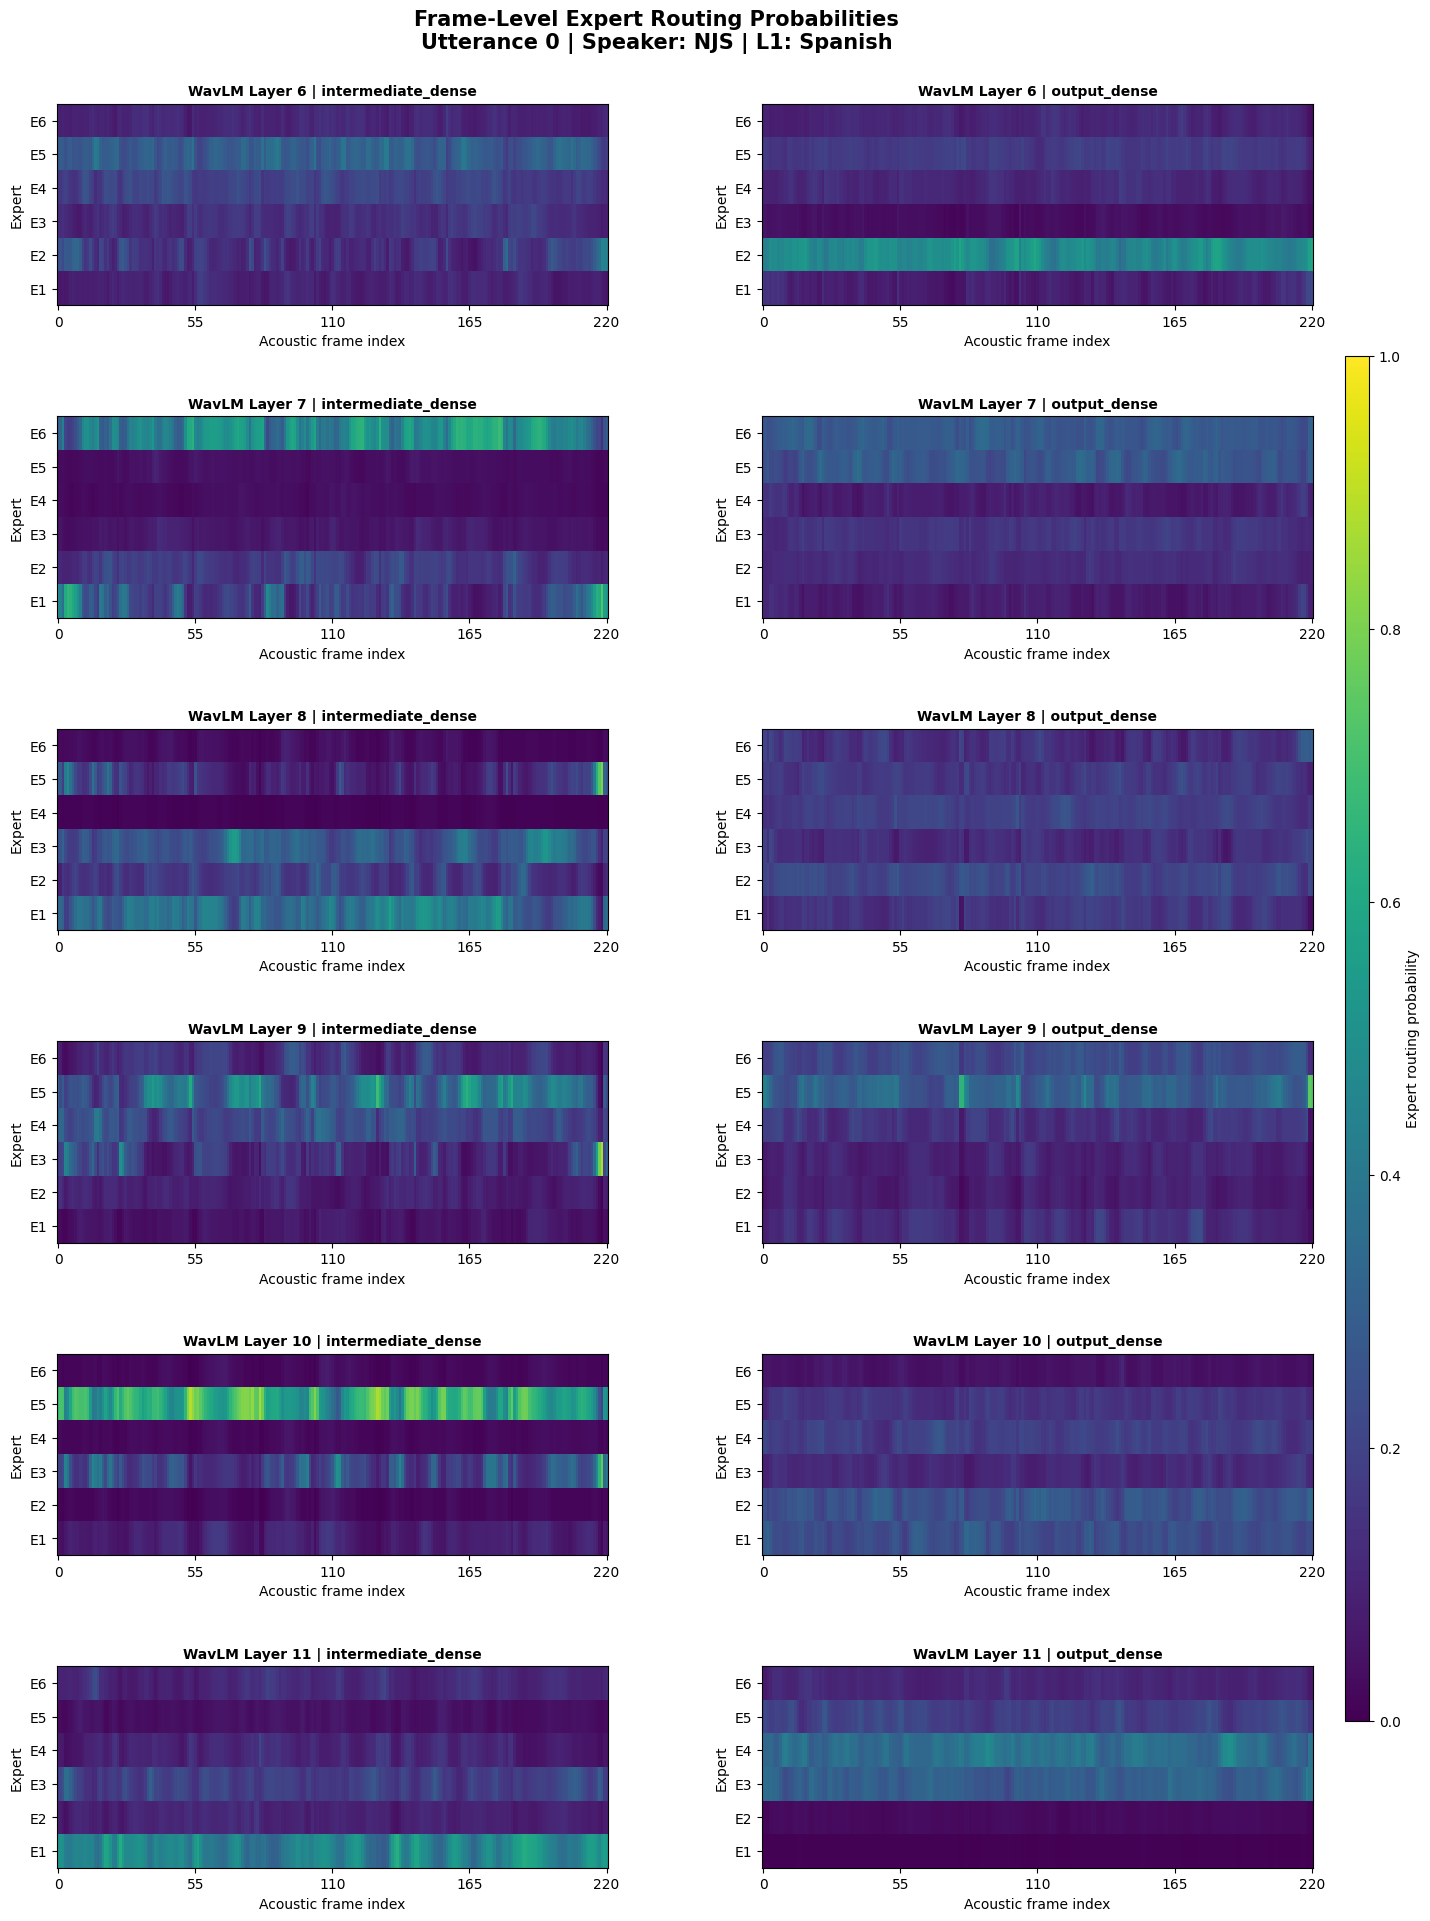

In [18]:
# Cell A8: Frame-Level Expert Routing Heatmaps

import matplotlib.pyplot as plt

# Select one representative utterance
sample_idx = 0

sample_metadata = test_dataset[sample_idx]
frame_data = frame_routing_by_utterance[sample_idx]

print("Representative utterance:")
print("Speaker:", sample_metadata["speaker_code"])
print("L1 background:", sample_metadata["speaker_native_language"])
print("Gender:", sample_metadata["speaker_gender"])

# Create 6 x 2 heatmap layout
fig, axes = plt.subplots(6, 2, figsize=(16, 21))

for ax, (name, weights) in zip(axes.flat, frame_data.items()):

    # Shape: (frames, 6 experts)
    matrix = weights.T

    image = ax.imshow(
        matrix,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    # Router identification
    layer = name.split(".layers.")[1].split(".")[0]
    projection = name.split(".")[-1]

    ax.set_title(
        f"WavLM Layer {layer} | {projection}",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel("Expert")
    ax.set_xlabel("Acoustic frame index")

    ax.set_yticks(range(6))
    ax.set_yticklabels([f"E{i+1}" for i in range(6)])

    n_frames = weights.shape[0]

    ax.set_xticks(
        np.linspace(0, n_frames - 1, 5, dtype=int)
    )

fig.suptitle(
    f"Frame-Level Expert Routing Probabilities\n"
    f"Utterance {sample_idx} | "
    f"Speaker: {sample_metadata['speaker_code']} | "
    f"L1: {sample_metadata['speaker_native_language']}",
    fontsize=15,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    right=0.91,
    top=0.95,
    hspace=0.55,
    wspace=0.28
)

# Shared colorbar
cax = fig.add_axes([0.93, 0.18, 0.015, 0.65])

fig.colorbar(
    image,
    cax=cax,
    label="Expert routing probability"
)

plt.savefig(
    project_dir / "A8_frame_level_expert_routing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Cell A9: L1-Wise Expert Routing Visualization

* **Purpose:** Investigates whether expert routing patterns differ across speakers with different native-language backgrounds.
* **Operations:** Generates comparative heatmaps using speaker-balanced mean routing probabilities for the six L1 groups across all 12 LoRA-MoE routers. A common colour scale is maintained to enable direct comparison between routers.

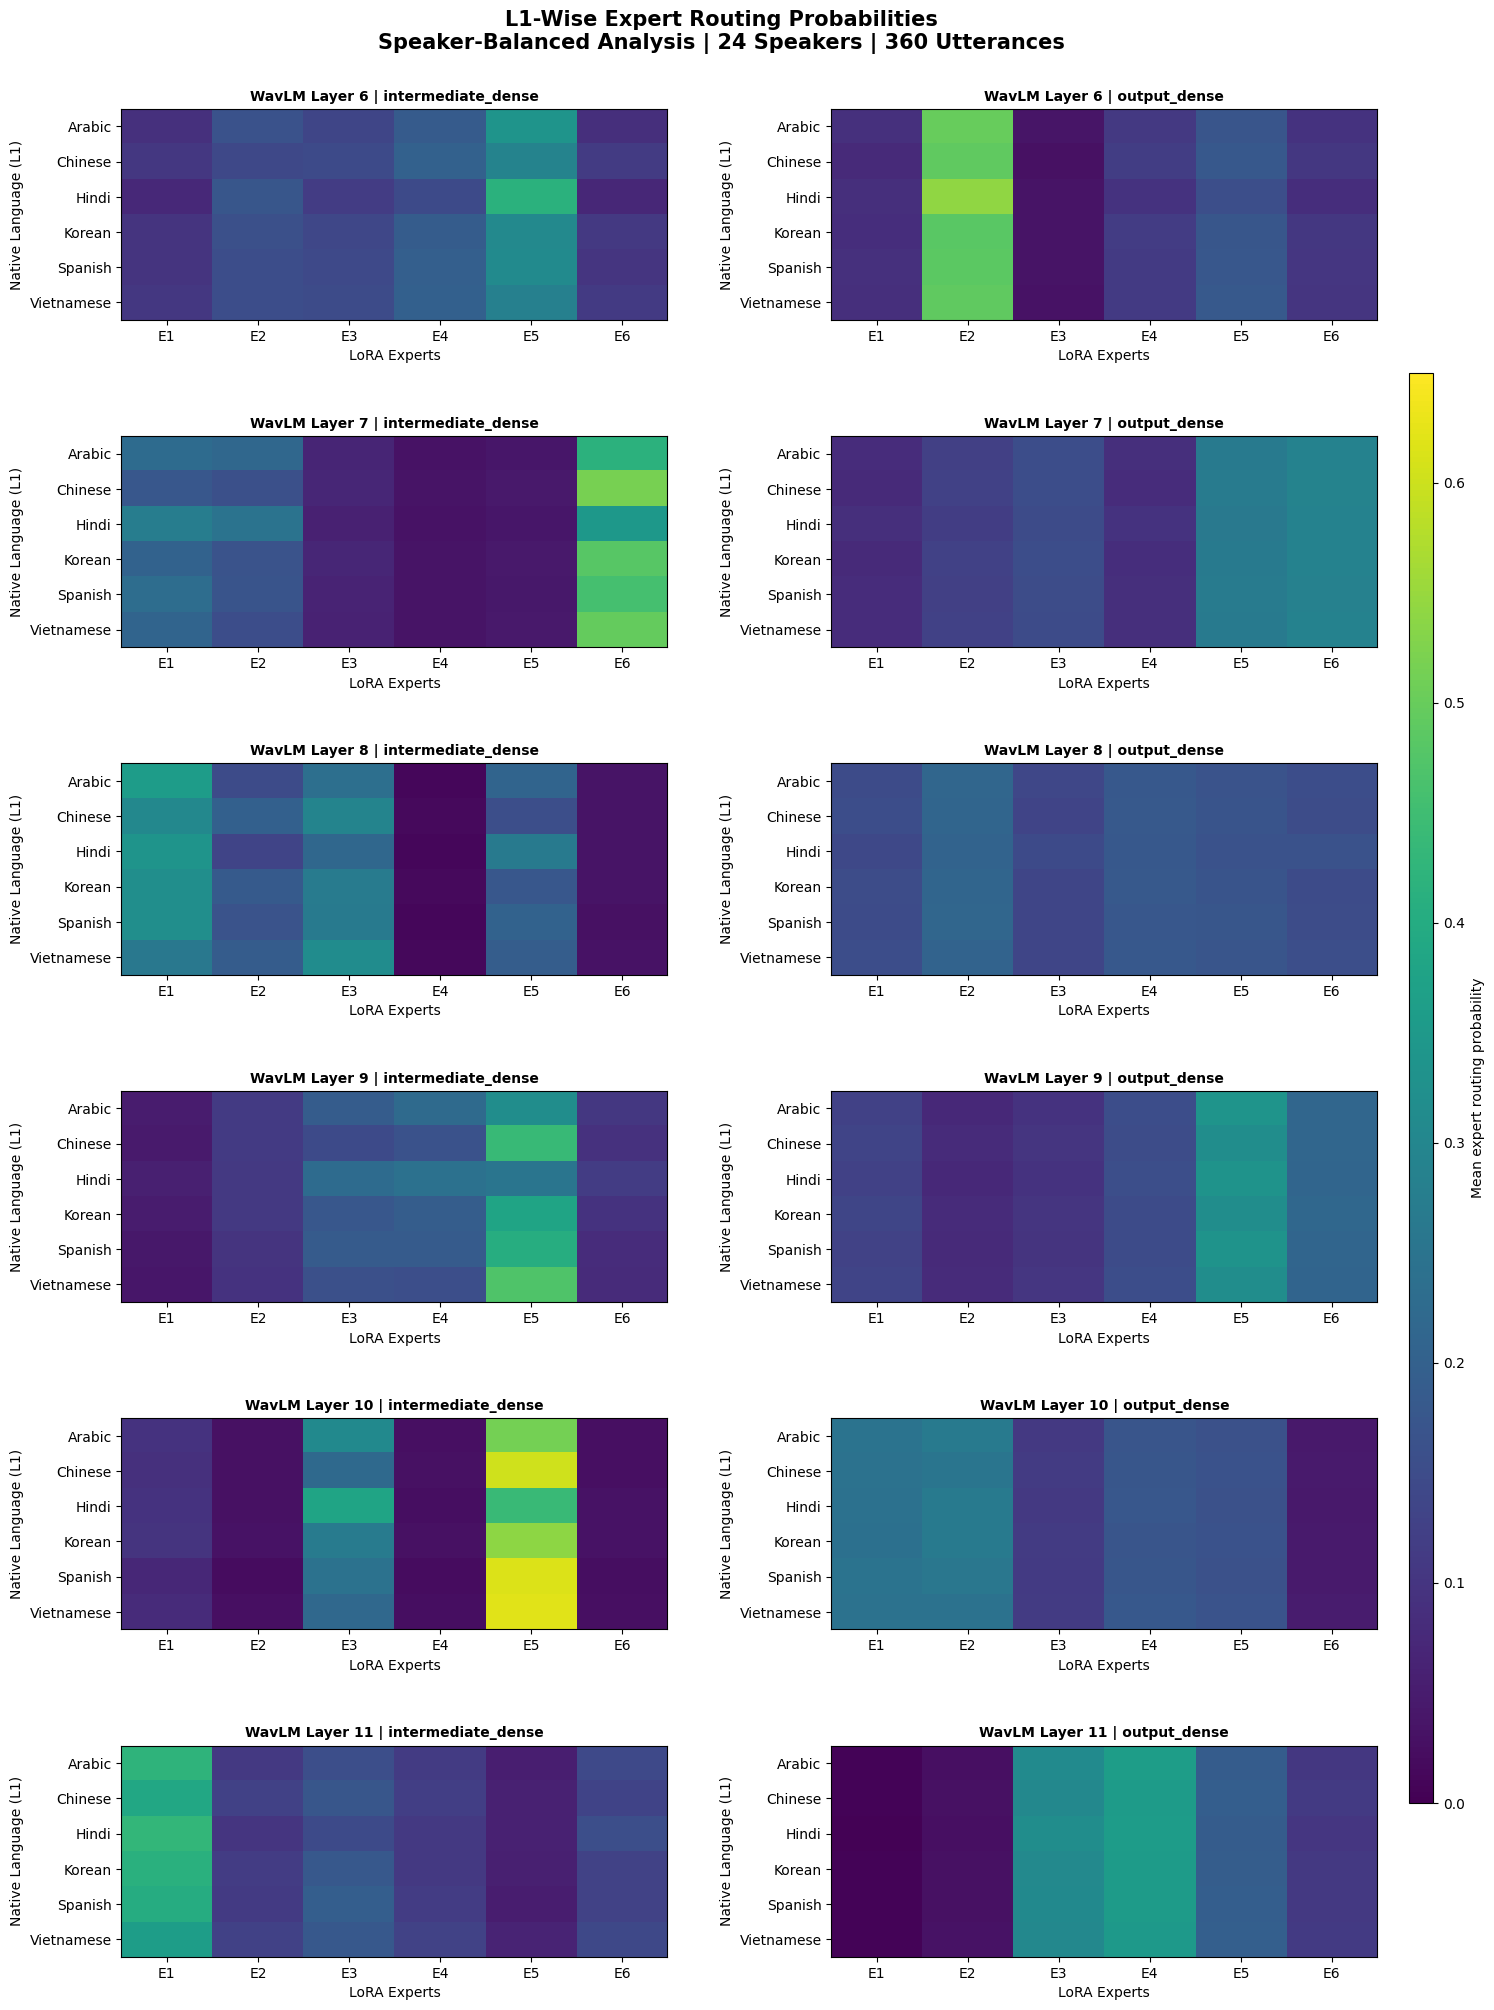

L1-wise heatmaps generated successfully.
Shared colour scale: 0 to 0.65
Numerical results saved.


In [19]:
# Cell A9: L1-Wise Expert Routing Heatmaps

fig, axes = plt.subplots(6, 2, figsize=(16, 22))

# Use a common colour scale across all 12 routers
global_max = max(
    l1_routing_df[cols].to_numpy().max()
    for cols in router_columns.values()
)

vmax = np.ceil(global_max * 20) / 20

for ax, (name, cols) in zip(axes.flat, router_columns.items()):

    # Rows: L1 groups | Columns: Experts
    matrix = (
        l1_routing_df
        .set_index("speaker_native_language")
        .loc[language_order, cols]
        .to_numpy()
    )

    image = ax.imshow(
        matrix,
        aspect="auto",
        cmap="viridis",
        vmin=0,
        vmax=vmax
    )

    layer = name.split(".layers.")[1].split(".")[0]
    projection = name.split(".")[-1]

    ax.set_title(
        f"WavLM Layer {layer} | {projection}",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_xticks(range(6))
    ax.set_xticklabels([f"E{i+1}" for i in range(6)])

    ax.set_yticks(range(6))
    ax.set_yticklabels(language_order)

    ax.set_xlabel("LoRA Experts")
    ax.set_ylabel("Native Language (L1)")

fig.suptitle(
    "L1-Wise Expert Routing Probabilities\n"
    "Speaker-Balanced Analysis | 24 Speakers | 360 Utterances",
    fontsize=15,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    right=0.91,
    top=0.95,
    hspace=0.55,
    wspace=0.30
)

# Shared colour bar
cax = fig.add_axes([0.93, 0.18, 0.015, 0.65])

fig.colorbar(
    image,
    cax=cax,
    label="Mean expert routing probability"
)

plt.savefig(
    project_dir / "A9_l1_wise_expert_routing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results for the report
l1_routing_df.to_csv(
    project_dir / "A9_l1_expert_activation_means.csv",
    index=False
)

print("L1-wise heatmaps generated successfully.")
print(f"Shared colour scale: 0 to {vmax:.2f}")
print("Numerical results saved.")

### Cell A10: Between-L1 and Within-L1 Variability Analysis

* **Purpose:** Evaluates whether differences in expert routing probabilities across native-language groups exceed ordinary speaker-to-speaker variation.
* **Operations:** Compares the standard deviation of L1-level mean routing probabilities with the average within-L1 speaker variation for every router-expert combination. This helps identify potentially L1-sensitive routing patterns without assuming expert specialization in advance.

VARIABILITY ANALYSIS

Top 12 router-expert combinations:


,router,layer,projection,expert,between_l1_std,within_l1_speaker_std,between_within_ratio,l1_mean_range
0,L6_output_dense,6,output_dense,E4,0.0074,0.0015,4.9090,0.0232
1,L6_intermediate_dense,6,intermediate_dense,E1,0.0105,0.0026,4.0221,0.0309
2,L6_output_dense,6,output_dense,E6,0.0066,0.0018,3.6313,0.0192
3,L7_intermediate_dense,7,intermediate_dense,E6,0.0567,0.0167,3.3952,0.1696
4,L6_intermediate_dense,6,intermediate_dense,E5,0.0444,0.0138,3.2243,0.1324
5,L6_intermediate_dense,6,intermediate_dense,E4,0.0191,0.0059,3.2157,0.0564
6,L7_intermediate_dense,7,intermediate_dense,E2,0.0345,0.0109,3.1629,0.0929
7,L6_output_dense,6,output_dense,E5,0.0080,0.0026,3.1264,0.0240
8,L11_output_dense,11,output_dense,E3,0.0054,0.0018,2.9702,0.0163
9,L6_intermediate_dense,6,intermediate_dense,E6,0.0141,0.0048,2.9287,0.0405


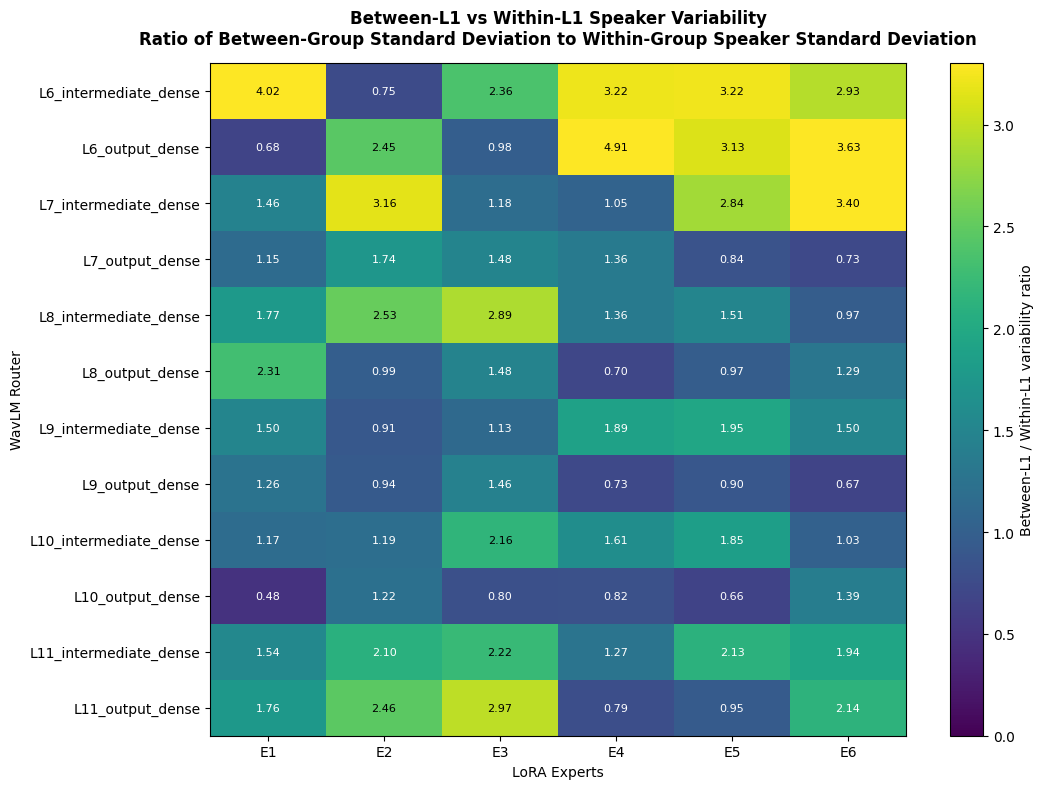


Analysis saved successfully.
Total router-expert combinations: 72


In [20]:
# Cell A10: Between-L1 vs Within-L1 Variability

variation_rows = []

for router_name, cols in router_columns.items():

    layer = router_name.split(".layers.")[1].split(".")[0]
    projection = router_name.split(".")[-1]

    for expert_idx, col in enumerate(cols):

        # Mean routing probability for each L1 group
        group_means = (
            l1_routing_df
            .set_index("speaker_native_language")[col]
            .reindex(language_order)
        )

        # Speaker-to-speaker variability within each L1
        within_stds = (
            speaker_routing_df
            .groupby("speaker_native_language")[col]
            .std(ddof=1)
            .reindex(language_order)
        )

        # Variation across the six L1 group means
        between_l1_std = group_means.std(ddof=0)

        # Average within-L1 speaker variability
        within_l1_std = within_stds.mean()

        ratio = between_l1_std / (within_l1_std + 1e-8)

        variation_rows.append({
            "router": f"L{layer}_{projection}",
            "layer": int(layer),
            "projection": projection,
            "expert": f"E{expert_idx + 1}",
            "between_l1_std": between_l1_std,
            "within_l1_speaker_std": within_l1_std,
            "between_within_ratio": ratio,
            "l1_mean_range": group_means.max() - group_means.min()
        })

variation_df = pd.DataFrame(variation_rows)

# Rank potentially L1-sensitive combinations
variation_df = variation_df.sort_values(
    "between_within_ratio",
    ascending=False
).reset_index(drop=True)

print("VARIABILITY ANALYSIS")
print("=" * 65)

print("\nTop 12 router-expert combinations:")
display(
    variation_df.head(12).round(4)
)

# Create ratio heatmap
ratio_matrix = variation_df.pivot(
    index="router",
    columns="expert",
    values="between_within_ratio"
)

router_order = [
    f"L{key.split('.layers.')[1].split('.')[0]}_{key.split('.')[-1]}"
    for key in router_columns
]

ratio_matrix = ratio_matrix.reindex(
    index=router_order,
    columns=[f"E{i}" for i in range(1, 7)]
)

fig, ax = plt.subplots(figsize=(11, 8))

plot_values = ratio_matrix.to_numpy()

vmax = max(
    float(np.nanpercentile(plot_values, 95)),
    1e-6
)

im = ax.imshow(
    plot_values,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=vmax
)

ax.set_xticks(range(6))
ax.set_xticklabels([f"E{i}" for i in range(1, 7)])

ax.set_yticks(range(len(router_order)))
ax.set_yticklabels(router_order)

ax.set_xlabel("LoRA Experts")
ax.set_ylabel("WavLM Router")

ax.set_title(
    "Between-L1 vs Within-L1 Speaker Variability\n"
    "Ratio of Between-Group Standard Deviation to "
    "Within-Group Speaker Standard Deviation",
    fontweight="bold",
    pad=14
)

# Display numerical ratios
for i in range(plot_values.shape[0]):
    for j in range(plot_values.shape[1]):
        ax.text(
            j, i,
            f"{plot_values[i, j]:.2f}",
            ha="center",
            va="center",
            color="white" if plot_values[i, j] < vmax * 0.65 else "black",
            fontsize=8
        )

fig.colorbar(
    im,
    ax=ax,
    label="Between-L1 / Within-L1 variability ratio"
)

plt.tight_layout()

plt.savefig(
    project_dir / "A10_l1_speaker_variability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save the complete numerical analysis
variation_df.to_csv(
    project_dir / "A10_l1_speaker_variability.csv",
    index=False
)

print("\nAnalysis saved successfully.")
print("Total router-expert combinations:", len(variation_df))

## Phase 5: Verified Phoneme Recognition Performance Analysis

### Speaker-Wise and L1-Wise PER

The saved full-test predictions are compared with the corresponding reference phoneme sequences. Utterance-level edit-distance counts are aggregated into:

- Individual PER for all 24 speakers.
- Pooled PER for each of the six L1 groups.
- Mean speaker PER and standard deviation within each L1 group.

Pooled L1 PER and mean speaker PER are reported separately because speakers contribute different numbers of utterances and reference phonemes.

In [21]:
import json
import hashlib
import numpy as np
import pandas as pd
import jiwer

# ============================================================
# 1. USE PREDICTIONS LOADED FROM THE PRIVATE HUGGING FACE REPO
# ============================================================

assert "prediction_data" in globals(), (
    "Run the Hugging Face prediction-loading cell first."
)
assert "project_dir" in globals(), (
    "Run the local project-directory setup cell first."
)

references = prediction_data["references"]
predictions = prediction_data["predictions"]

assert len(references) == 360
assert len(predictions) == 360

sequence_hash = hashlib.sha256(
    json.dumps(
        prediction_data,
        ensure_ascii=False,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

expected_hash = (
    "5281ed165060c54ebca01d4af9bbd67"
    "cd3de7ae33ef43d3562f7fd057233f369"
)

assert sequence_hash == expected_hash, (
    "Prediction sequence hash mismatch. Stop analysis."
)

# Verify metadata order directly against the reconstructed test split.
dataset_speakers = [
    str(value) for value in test_dataset["speaker_code"]
]
dataset_languages = [
    str(value) for value in test_dataset["speaker_native_language"]
]

assert dataset_speakers == routing_df["speaker_code"].astype(str).tolist()
assert dataset_languages == routing_df["speaker_native_language"].astype(str).tolist()

print("Verified predictions loaded:", len(references))
print("Sequence SHA-256:", sequence_hash)
print("Prediction reference order and routing metadata order verified.")

# ============================================================
# 2. VALIDATE SPEAKER AND L1 METADATA FROM A6
# ============================================================

assert "routing_df" in globals(), (
    "routing_df unavailable. Execute A2-A6 first."
)

required_columns = [
    "speaker_code",
    "speaker_native_language"
]

assert all(
    col in routing_df.columns
    for col in required_columns
), "Required metadata columns missing."

metadata = (
    routing_df[required_columns]
    .copy()
    .reset_index(drop=True)
)

assert len(metadata) == 360
assert not metadata.isnull().any().any()

metadata = metadata.rename(columns={
    "speaker_code": "speaker",
    "speaker_native_language": "l1"
})

# Each speaker must belong to exactly one L1 group
speaker_l1_counts = (
    metadata.groupby("speaker")["l1"].nunique()
)

assert (speaker_l1_counts == 1).all()

assert metadata["speaker"].nunique() == 24
assert metadata["l1"].nunique() == 6

print("\nMetadata verification successful.")
print("Utterances:", len(metadata))
print("Speakers:", metadata["speaker"].nunique())
print("L1 groups:", sorted(metadata["l1"].unique()))


# ============================================================
# 3. CALCULATE UTTERANCE-LEVEL ERROR COUNTS
# ============================================================

utterance_results = []

for i, (ref, pred) in enumerate(
    zip(references, predictions)
):

    result = jiwer.process_words([ref], [pred])

    S = result.substitutions
    D = result.deletions
    I = result.insertions
    H = result.hits

    reference_phones = len(ref.split())

    assert reference_phones == S + D + H

    utterance_results.append({
        "utterance_index": i,
        "reference_phones": reference_phones,
        "substitutions": S,
        "deletions": D,
        "insertions": I,
        "hits": H,
        "errors": S + D + I,
        "PER_percent": (
            100 * (S + D + I) / reference_phones
        )
    })

utterance_df = pd.concat(
    [
        metadata,
        pd.DataFrame(utterance_results)
    ],
    axis=1
)

assert len(utterance_df) == 360


# ============================================================
# 4. SPEAKER-WISE PER
# ============================================================

speaker_df = (
    utterance_df
    .groupby(
        ["l1", "speaker"],
        as_index=False
    )
    .agg(
        utterances=("utterance_index", "count"),
        reference_phones=("reference_phones", "sum"),
        substitutions=("substitutions", "sum"),
        deletions=("deletions", "sum"),
        insertions=("insertions", "sum"),
        hits=("hits", "sum"),
        errors=("errors", "sum")
    )
)

speaker_df["PER_percent"] = (
    100 * speaker_df["errors"]
    / speaker_df["reference_phones"]
)

assert len(speaker_df) == 24
assert speaker_df["speaker"].nunique() == 24


# ============================================================
# 5. L1-WISE POOLED PER
# ============================================================

l1_df = (
    utterance_df
    .groupby("l1", as_index=False)
    .agg(
        utterances=("utterance_index", "count"),
        reference_phones=("reference_phones", "sum"),
        substitutions=("substitutions", "sum"),
        deletions=("deletions", "sum"),
        insertions=("insertions", "sum"),
        hits=("hits", "sum"),
        errors=("errors", "sum")
    )
)

l1_df["PER_percent"] = (
    100 * l1_df["errors"]
    / l1_df["reference_phones"]
)


# ============================================================
# 6. SPEAKER-BALANCED L1 STATISTICS
# ============================================================

speaker_balanced = (
    speaker_df
    .groupby("l1")
    .agg(
        speakers=("speaker", "nunique"),
        mean_speaker_PER=("PER_percent", "mean"),
        SD_speaker_PER=("PER_percent", "std"),
        minimum_speaker_PER=("PER_percent", "min"),
        maximum_speaker_PER=("PER_percent", "max")
    )
    .reset_index()
)

l1_df = l1_df.merge(
    speaker_balanced,
    on="l1"
)

assert l1_df["speakers"].eq(4).all()
assert len(l1_df) == 6


# ============================================================
# 7. VERIFY AGAINST CURRENT CANONICAL FULL-TEST RESULT
# ============================================================

total_reference = utterance_df["reference_phones"].sum()
total_errors = utterance_df["errors"].sum()

overall_per = (
    100 * total_errors / total_reference
)

actual_counts = {
    "substitutions": int(utterance_df["substitutions"].sum()),
    "deletions": int(utterance_df["deletions"].sum()),
    "insertions": int(utterance_df["insertions"].sum()),
    "hits": int(utterance_df["hits"].sum()),
    "reference_phones": int(total_reference)
}

expected_counts = {
    "substitutions": 1110,
    "deletions": 193,
    "insertions": 210,
    "hits": 10202,
    "reference_phones": 11505
}

assert actual_counts == expected_counts, (
    f"Overall metric verification failed: {actual_counts}"
)

print("\n========== OVERALL VERIFICATION PASSED ==========")
print("Full-test strict PER:", round(overall_per, 6), "%")
print("Error counts:", actual_counts)


# ============================================================
# 8. SAVE ALL THREE ANALYSIS FILES TO THE LOCAL PROJECT FOLDER
# ============================================================

utterance_path = (
    project_dir / "verified_360_utterance_PER.csv"
)

speaker_path = (
    project_dir / "verified_360_speaker_PER.csv"
)

l1_path = (
    project_dir / "verified_360_L1_PER.csv"
)

utterance_df.to_csv(utterance_path, index=False)
speaker_df.to_csv(speaker_path, index=False)
l1_df.to_csv(l1_path, index=False)

for path in [utterance_path, speaker_path, l1_path]:
    assert path.exists() and path.stat().st_size > 0

print("\n========== FILES SAVED ==========")
print(utterance_path)
print(speaker_path)
print(l1_path)


# ============================================================
# 9. DISPLAY RESULTS
# ============================================================

print("\n========== SPEAKER-WISE PER ==========")

print(
    speaker_df.sort_values(
        ["l1", "PER_percent"]
    ).round(3).to_string(index=False)
)

print("\n========== L1-WISE PER ==========")

print(
    l1_df.sort_values(
        "PER_percent",
        ascending=False
    ).round(3).to_string(index=False)
)

print("\nALL ANALYSES COMPLETED SUCCESSFULLY.")

Verified predictions loaded: 360
Sequence SHA-256: 5281ed165060c54ebca01d4af9bbd67cd3de7ae33ef43d3562f7fd057233f369
Prediction reference order and routing metadata order verified.

Metadata verification successful.
Utterances: 360
Speakers: 24
L1 groups: ['Arabic', 'Chinese', 'Hindi', 'Korean', 'Spanish', 'Vietnamese']

========== OVERALL VERIFICATION PASSED ==========
Full-test strict PER: 13.150804 %
Error counts: {'substitutions': 1110, 'deletions': 193, 'insertions': 210, 'hits': 10202, 'reference_phones': 11505}

========== FILES SAVED ==========
/content/MDD_Project/verified_360_utterance_PER.csv
/content/MDD_Project/verified_360_speaker_PER.csv
/content/MDD_Project/verified_360_L1_PER.csv

========== SPEAKER-WISE PER ==========
        l1 speaker  utterances  reference_phones  substitutions  deletions  insertions  hits  errors  PER_percent
    Arabic     ABA          13               402             25          3          11   374      39        9.701
    Arabic    YBAA         

### Phoneme-Level Error and Confusion Analysis

Use sequence alignment between the verified references and predictions to identify substitutions, deletions, insertions and reference-phoneme error rates. These findings describe acoustic recognition behavior; they do not by themselves establish articulatory causes of pronunciation errors.

In [22]:
assert "references" in globals() and "predictions" in globals()
assert len(references) == 360 and len(predictions) == 360
assert "project_dir" in globals()


import json
import jiwer
import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter

# ============================================================
# 2. INITIALIZE ERROR COUNTERS
# ============================================================

reference_counts = Counter()
substitution_by_reference = Counter()
deletion_counts = Counter()
insertion_counts = Counter()
hit_counts = Counter()
substitution_pairs = Counter()

for ref, pred in zip(references, predictions):
    reference_counts.update(ref.split())

# ============================================================
# 3. EXTRACT EDIT-DISTANCE ALIGNMENTS
# ============================================================

for ref, pred in zip(references, predictions):

    ref_tokens = ref.split()
    hyp_tokens = pred.split()

    result = jiwer.process_words([ref], [pred])

    for chunk in result.alignments[0]:

        r = ref_tokens[
            chunk.ref_start_idx:chunk.ref_end_idx
        ]

        h = hyp_tokens[
            chunk.hyp_start_idx:chunk.hyp_end_idx
        ]

        if chunk.type == "equal":

            assert len(r) == len(h)

            for phone in r:
                hit_counts[phone] += 1

        elif chunk.type == "substitute":

            assert len(r) == len(h), (
                "Unexpected unequal substitution alignment."
            )

            for ref_phone, hyp_phone in zip(r, h):

                substitution_by_reference[ref_phone] += 1

                substitution_pairs[
                    (ref_phone, hyp_phone)
                ] += 1

        elif chunk.type == "delete":

            for phone in r:
                deletion_counts[phone] += 1

        elif chunk.type == "insert":

            for phone in h:
                insertion_counts[phone] += 1

        else:
            raise ValueError(
                f"Unexpected alignment type: {chunk.type}"
            )

# ============================================================
# 4. VERIFY ALL COUNTS AGAINST OVERALL PER
# ============================================================

total_hits = sum(hit_counts.values())
total_substitutions = sum(
    substitution_by_reference.values()
)
total_deletions = sum(deletion_counts.values())
total_insertions = sum(insertion_counts.values())
total_reference = sum(reference_counts.values())

assert total_reference == 11505
assert total_hits == 10202
assert total_substitutions == 1110
assert total_deletions == 193
assert total_insertions == 210

print("========== ALIGNMENT VERIFICATION PASSED ==========")
print("Reference phonemes:", total_reference)
print("Hits:", total_hits)
print("Substitutions:", total_substitutions)
print("Deletions:", total_deletions)
print("Insertions:", total_insertions)

# ============================================================
# 5. PHONEME-WISE ERROR SUMMARY
# ============================================================

phone_rows = []

for phone, occurrences in reference_counts.items():

    sub = substitution_by_reference[phone]
    dele = deletion_counts[phone]
    hit = hit_counts[phone]

    errors = sub + dele

    phone_rows.append({
        "phoneme": phone,
        "reference_occurrences": occurrences,
        "correct_hits": hit,
        "substitutions": sub,
        "deletions": dele,
        "reference_errors": errors,
        "substitution_rate_percent": 100 * sub / occurrences,
        "deletion_rate_percent": 100 * dele / occurrences,
        "reference_error_rate_percent": (
            100 * errors / occurrences
        ),
        "correct_match_rate_percent": (
            100 * hit / occurrences
        )
    })

phoneme_df = pd.DataFrame(phone_rows)

phoneme_df = phoneme_df.sort_values(
    "reference_error_rate_percent",
    ascending=False
).reset_index(drop=True)

# ============================================================
# 6. SUBSTITUTION CONFUSION ANALYSIS
# ============================================================

confusion_rows = []

for (ref_phone, hyp_phone), count in substitution_pairs.items():

    confusion_rows.append({
        "reference_phone": ref_phone,
        "predicted_phone": hyp_phone,
        "count": count,
        "percentage_of_all_substitutions": (
            100 * count / total_substitutions
        )
    })

confusion_df = pd.DataFrame(confusion_rows)

confusion_df = confusion_df.sort_values(
    "count",
    ascending=False
).reset_index(drop=True)

# ============================================================
# 7. DELETION SUMMARY
# ============================================================

deletion_df = pd.DataFrame([
    {
        "phoneme": phone,
        "deletion_count": count,
        "percentage_of_all_deletions": (
            100 * count / total_deletions
        )
    }
    for phone, count in deletion_counts.items()
])

deletion_df = deletion_df.sort_values(
    "deletion_count",
    ascending=False
).reset_index(drop=True)

# ============================================================
# 8. INSERTION SUMMARY
# ============================================================

insertion_df = pd.DataFrame([
    {
        "phoneme": phone,
        "insertion_count": count,
        "percentage_of_all_insertions": (
            100 * count / total_insertions
        )
    }
    for phone, count in insertion_counts.items()
])

insertion_df = insertion_df.sort_values(
    "insertion_count",
    ascending=False
).reset_index(drop=True)

# ============================================================
# 9. SAVE ALL RESULTS TO THE LOCAL PROJECT FOLDER
# ============================================================

phoneme_path = project_dir / "phoneme_error_summary.csv"
confusion_path = project_dir / "phoneme_substitution_confusions.csv"
deletion_path = project_dir / "phoneme_deletion_summary.csv"
insertion_path = project_dir / "phoneme_insertion_summary.csv"

phoneme_df.to_csv(phoneme_path, index=False)
confusion_df.to_csv(confusion_path, index=False)
deletion_df.to_csv(deletion_path, index=False)
insertion_df.to_csv(insertion_path, index=False)

for path in [
    phoneme_path,
    confusion_path,
    deletion_path,
    insertion_path
]:
    assert path.exists() and path.stat().st_size > 0

# ============================================================
# 10. DISPLAY MOST IMPORTANT FINDINGS
# ============================================================

print("\n========== TOP 15 PHONEMES BY ERROR RATE ==========")

print(
    phoneme_df.head(15).round(3).to_string(index=False)
)

print("\n========== TOP 20 SUBSTITUTION CONFUSIONS ==========")

print(
    confusion_df.head(20).round(3).to_string(index=False)
)

print("\n========== DELETION FREQUENCY ==========")

print(
    deletion_df.head(15).round(3).to_string(index=False)
)

print("\n========== INSERTION FREQUENCY ==========")

print(
    insertion_df.head(15).round(3).to_string(index=False)
)

print("\n========== OUTPUT FILES ==========")

for path in [
    phoneme_path,
    confusion_path,
    deletion_path,
    insertion_path
]:
    print(path)

print("\nPHONEME-LEVEL ANALYSIS COMPLETED SUCCESSFULLY.")

========== ALIGNMENT VERIFICATION PASSED ==========
Reference phonemes: 11505
Hits: 10202
Substitutions: 1110
Deletions: 193
Insertions: 210

========== TOP 15 PHONEMES BY ERROR RATE ==========
phoneme  reference_occurrences  correct_hits  substitutions  deletions  reference_errors  substitution_rate_percent  deletion_rate_percent  reference_error_rate_percent  correct_match_rate_percent
     DH                    174           100             69          5                74                     39.655                  2.874                        42.529                      57.471
     AA                    186           119             65          2                67                     34.946                  1.075                        36.022                      63.978
     ZH                     14             9              5          0                 5                     35.714                  0.000                        35.714                      64.286
      Z           

## Phase 6: Persist Final Experimental Artifacts to Hugging Face

All prediction, routing, visualization, speaker/L1 and phoneme-level outputs are saved under `project_dir`. The following cell uploads the complete folder to the private Hugging Face Dataset repository under `results/`.

In [23]:
assert project_dir.exists(), "Project directory does not exist."
assert (project_dir / "final_360_test_predictions.json").exists(), (
    "Verified prediction JSON is missing from the project folder."
)

upload_result = api.upload_folder(
    folder_path=str(project_dir),
    repo_id=REPO_ID,
    repo_type="dataset",
    path_in_repo="results"
)

print("All project artifacts uploaded to Hugging Face.")
print("Repository:", REPO_ID)
print("Repository path: results/")

All project artifacts uploaded to Hugging Face.
Repository: hsuyip05/mdd-analysis-artifacts
Repository path: results/


## Final Experimental Summary

### Full-Test Recognition Performance

The current canonical full-test evaluation covers 360 L2-Arctic test utterances from 24 speakers across six L1 groups, with 11,505 reference phonemes.

**Strict 39-class PER: 13.150804%**

| Metric | Count |
|---|---:|
| Substitutions | 1,110 |
| Deletions | 193 |
| Insertions | 210 |
| Correct matches (hits) | 10,202 |
| Reference phonemes | 11,505 |

**Allophone-equivalence PER: 9.195199%**

### Scope and Limitations

- The current notebook covers acoustic phoneme recognition and post-training analysis; complete phone-level MDD alignment and articulatory diagnosis remain future work.
- The test split is utterance-level rather than speaker-disjoint. Results should not be described as generalization to entirely unseen speakers.
- The original Stage 2 training code names its loader `balanced_train_loader`, but implements a standard shuffled utterance-level DataLoader rather than an explicit per-speaker/per-L1 balanced sampler.
- Each L1 group contains four speakers. L1 comparisons and expert-routing variability are descriptive and exploratory; statistical significance and accent-specific expert specialization have not been established.
- The equivalence PER uses the predefined allophone mapping and adjacent-repeat collapsing, so it is more permissive than strict 39-class PER.

The full prediction sequence and derived analysis artifacts are stored in the private Hugging Face analysis repository.